# Figure S3D — CAID3 Disorder-PDB ranking by MCC (top 40)

The 40 best CAID3 disorder predictors ranked by Matthews correlation coefficient (MCC) at each method's Fmax threshold (this is the MCC reported by the CAID3 pipeline). metapredict V1, V2 and V3 are coloured wherever they fall within the top 40.

**How it is made.** Every CAID3 disorder predictor (binding and linker predictors excluded) is scored on all covered, non-excluded residues of the CAID3 Disorder-PDB reference pooled together, reproducing the CAID3 ranking. Predictions are the CAID3 submission files in the shared data directory, except metapredict, which is predicted with metapredict 3.1.0 (`data/metapredict_caid/`). Unlike Figure 1C, which scores each method's own binary calls, AUC, APS and Fmax (panels A–C) use the continuous scores and so do not depend on any method's disorder threshold; the MCC in panel D is taken at each method's own Fmax threshold (FoldUnfold and NeProc-disorder submitted only binary states).

**Output:** `figures/figure_S03D.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid3_panels import (load_predictions, load_reference, metric_panel,
                          print_metapredict_ranks, rank_predictors)
from figtools import apply_style, require_metapredict_3_1, save_panel

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TOP_N = 40

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
reference = load_reference()
ranking = rank_predictors(reference, load_predictions())
print_metapredict_ranks(ranking)

AUC   V1 0.887 (rank 45/66), V2 0.915 (rank 30/66), V3 0.929 (rank 14/66)
APS   V1 0.837 (rank 38/66), V2 0.875 (rank 18/66), V3 0.902 (rank 7/66)
FMAX  V1 0.749 (rank 43/66), V2 0.804 (rank 19/66), V3 0.828 (rank 8/66)
MCC   V1 0.640 (rank 41/66), V2 0.721 (rank 18/66), V3 0.761 (rank 7/66)


Wrote figures/figure_S03D.pdf


PosixPath('figures/figure_S03D.pdf')

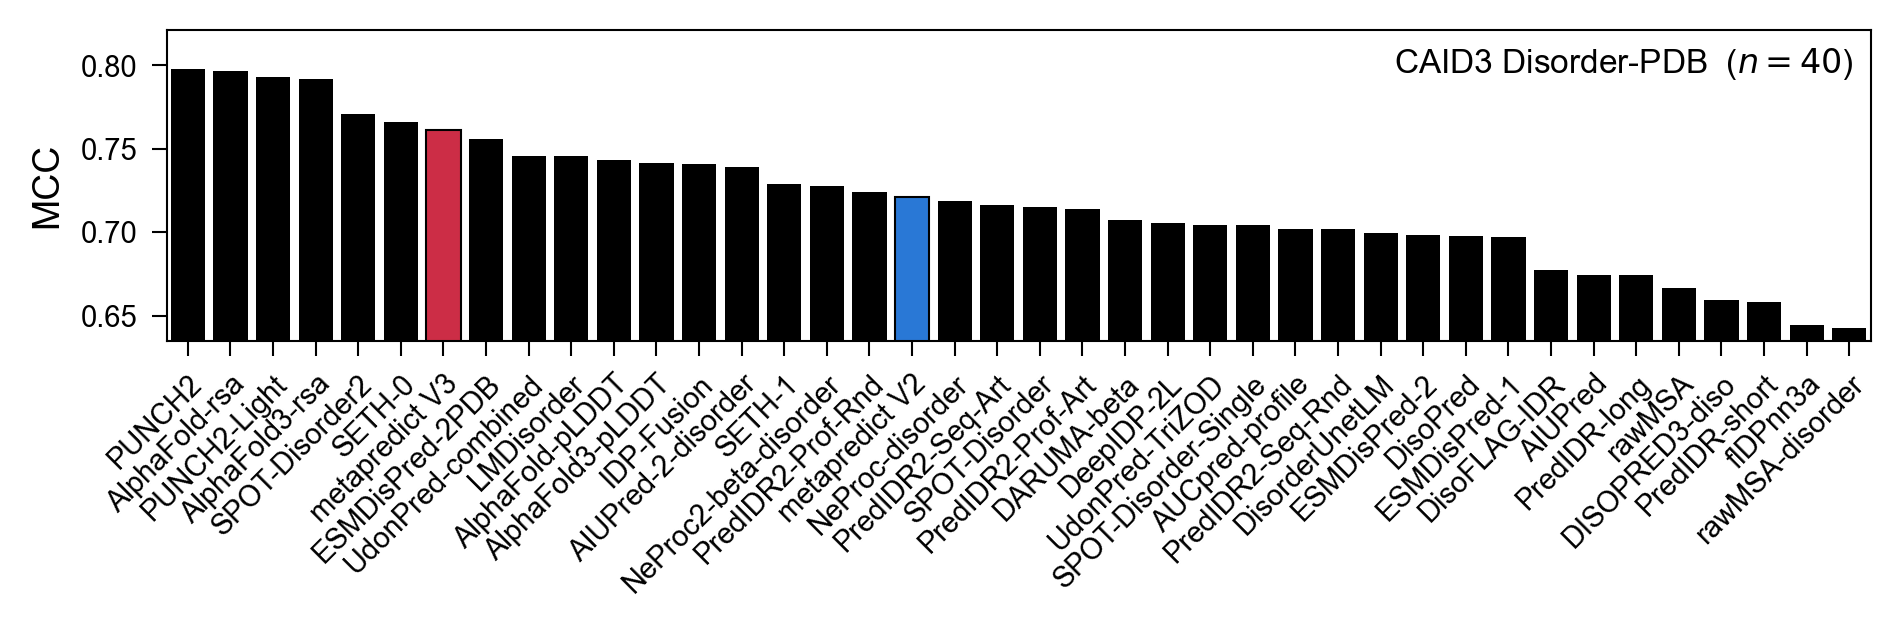

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.2), dpi=150)
metric_panel(ax, ranking, 'mcc', 'MCC', 'CAID3 Disorder-PDB', top_n=TOP_N)
plt.tight_layout()
save_panel(fig, 'figure_S03D')